[debug] Z_GRID has 33 nodes
baseline z_reio = 7.639, y_star = 25.393
[bracket] trying w=1.3778, f=-0.017892
[bracket] trying w=3.5271, f=-0.013122
[bracket] trying w=0.8611, f=-0.019038
[bracket] trying w=5.6434, f=-0.008423
[bracket] trying w=0.5382, f=-0.019755
[bracket] trying w=9.0294, f=-0.000900
[bracket] trying w=0.3364, f=-0.020202
[bracket] trying w=14.4470, f=0.011139
triangle: w = 9.4344, y_star = 26.0063
[bracket] trying w=1.3778, f=-0.018911
[bracket] trying w=3.5271, f=-0.015730
[bracket] trying w=0.8611, f=-0.019675
[bracket] trying w=5.6434, f=-0.012596
[bracket] trying w=0.5382, f=-0.020152
[bracket] trying w=9.0294, f=-0.007580
[bracket] trying w=0.3364, f=-0.020451
[bracket] trying w=14.4470, f=0.000454
asymmetric: w = 14.1413, y_star = 30.7131
[bracket] trying w=1.3778, f=-0.000729
[bracket] trying w=3.5271, f=-0.000758
[bracket] trying w=0.8611, f=-0.000722
[bracket] trying w=5.6434, f=-0.000789
[bracket] trying w=0.5382, f=-0.000718
[bracket] trying w=9.0294, f=-0

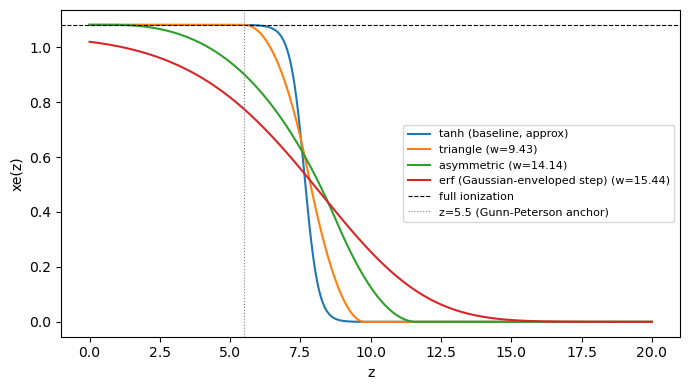

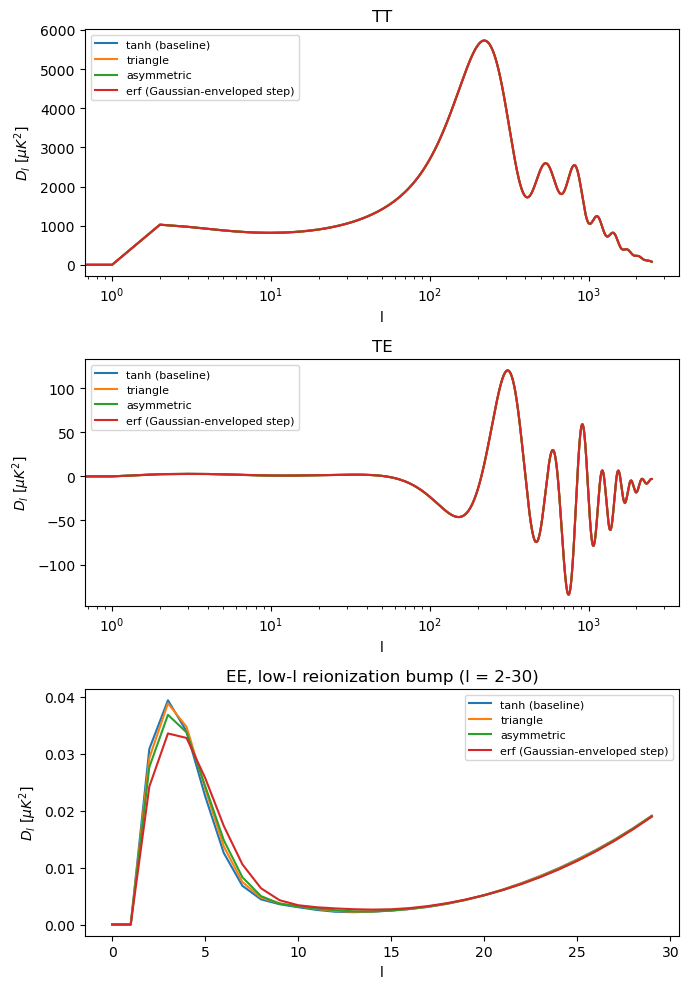

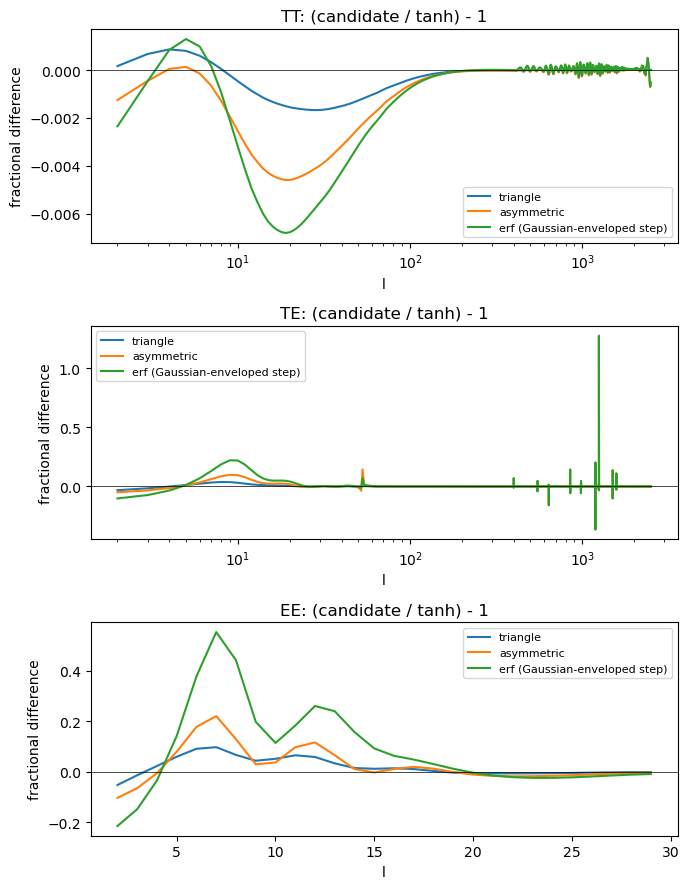

[bracket] trying w=1.3778, f=-0.017892
[bracket] trying w=3.5271, f=-0.013122
[bracket] trying w=0.8611, f=-0.019038
[bracket] trying w=5.6434, f=-0.008423
[bracket] trying w=0.5382, f=-0.019755
[bracket] trying w=9.0294, f=-0.000900
[bracket] trying w=0.3364, f=-0.020202
[bracket] trying w=14.4470, f=0.011139
r=1.0: w=9.4344, y_star=26.0063
[bracket] trying w=1.3778, f=-0.018401
[bracket] trying w=3.5271, f=-0.014426
[bracket] trying w=0.8611, f=-0.019357
[bracket] trying w=5.6434, f=-0.010510
[bracket] trying w=0.5382, f=-0.019953
[bracket] trying w=9.0294, f=-0.004241
[bracket] trying w=0.3364, f=-0.020326
[bracket] trying w=14.4470, f=0.005792
r=1.5: w=11.3198, y_star=27.8916
[bracket] trying w=1.3778, f=-0.018911
[bracket] trying w=3.5271, f=-0.015730
[bracket] trying w=0.8611, f=-0.019675
[bracket] trying w=5.6434, f=-0.012596
[bracket] trying w=0.5382, f=-0.020152
[bracket] trying w=9.0294, f=-0.007580
[bracket] trying w=0.3364, f=-0.020451
[bracket] trying w=14.4470, f=0.000454

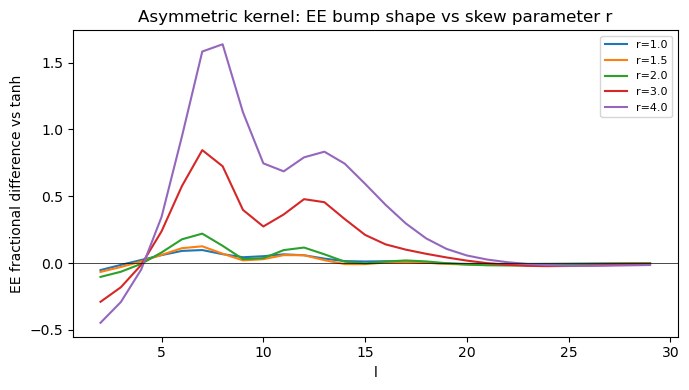

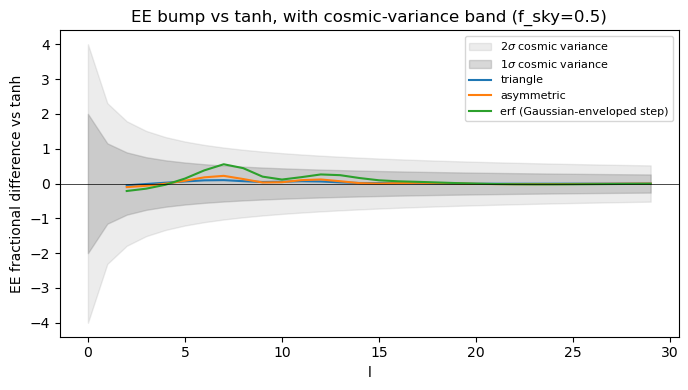

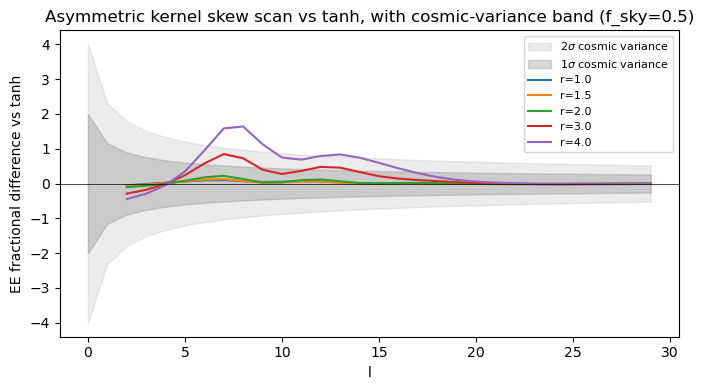

In [ ]:
# # Tanh alternatives for reionization: triangle / asymmetric / erf kernels
#
# Goal: hold total tau_reio fixed matched to the tanh baseline and vary only the
# shape of the ionization-fraction kernel, then compare TT/TE/EE Cls.
#
# CLASS tanh parametrization:
#   xe(z) = (1 + f_He) * F( (y_star - y(z)) / w )
#  y(z) = (1+z)**1.5, 
# F is a CDF that goes 0 -> 1, y_star sets the transition
# location, and w sets its width. For tanh, F(u) = 0.5*(1+tanh(u))
#


import numpy as np
from scipy.optimize import brentq
from scipy.special import erf
import matplotlib.pyplot as plt
from classy import Class

# ## y(z) transform and baseline tanh CDF

def y_of_z(z):
    return (1.0 + z) ** 1.5

def tanh_cdf(u):
    return 0.5 * (1.0 + np.tanh(u))

# ## Candidate kernels
#
# Each F(u) below requires F(-inf) = 0, F(+inf) = 1, monotonic. `u` is (y_star - y(z)) / w

def triangle_cdf(u):
    """Symmetric triangular density on u in [-1, 1]"""
    u = np.asarray(u, dtype=float)
    out = np.where(u < -1, 0.0,
          np.where(u < 0, 0.5 * (u + 1) ** 2,
          np.where(u < 1, 1 - 0.5 * (1 - u) ** 2, 1.0)))
    return out

def asym_triangle_cdf(u, r=2.0):
    """
    Asymmetric triangular left half-width 1, right half-width r
    Peak height chosen so the density integrates to 1.
    """
    u = np.asarray(u, dtype=float)
    h = 2.0 / (1.0 + r)  # peak density at u=0
    out = np.where(u < -1, 0.0,
          np.where(u < 0, (h / 2.0) * (u + 1) ** 2,
          np.where(u < r, h / 2.0 + h * (u - 0.0) - (h / (2.0 * r)) * u ** 2, 1.0)))
    # renormalize numerically to guard against the piecewise algebra above
    return np.clip(out, 0.0, 1.0)

def erf_cdf(u):
    """undo the Gaussian envelope of a step function: F(u) = 0.5*(1 + erf(u/sqrt(2))), which is trading the logistic tanh for a Gaussian-smoothed step.
     The width parameter w is the standard deviation of the Gaussian."""
    return 0.5 * (1.0 + erf(u / np.sqrt(2.0)))

KERNELS = {
    "tanh (baseline)": lambda u: tanh_cdf(u),
    "triangle":        lambda u: triangle_cdf(u),
    "asymmetric":      lambda u: asym_triangle_cdf(u, r=2.0),
    "erf (Gaussian-enveloped step)": lambda u: erf_cdf(u),
}


# ## Build an xe(z) node table for CLASS's reio_inter mode
#
# f_He set from the same Y_He/ helium mass fraction convention CLASS uses internally
# for the *primary* (HI + HeI) ionization step. No z ~3.5 HeII bump is included here, so the total ionization fraction never exceeds 1 + f_He.

# %%
F_HE = 0.0813  # rough default consistent with Y_He ~ 0.245;
XE_FLOOR = 2.0e-4  # residual free-electron fraction from recombination;
                    # kernels (triangle, asymmetric) hit an exact 0.0 for u < -1,
                    # which makes CLASS's opacity-rate calculation diverge
                    # (thermodynamics_calculate_opticals: dkappa == 0). 


#Claude suggestion: resize the grid adaptively for each kernel's width and transition location, r
# ather than using a fixed grid for all kernels. 
# This avoids undersampling the transition region for wider kernels.

def build_xe_table(cdf_func, y_star, w, z_grid):
    u = (y_star - y_of_z(z_grid)) / w
    xe = (1.0 + F_HE) * cdf_func(u)
    xe = np.maximum(xe, XE_FLOOR)
    # CLASS's reio_inter requires the last (highest-z) node to be exactly 0.0 --
    # it hands off to its own recombination-era history beyond this table, and
    # enforces that boundary explicitly (thermodynamics_set_parameters_reionization).
    # z_grid is ascending, so index -1 is the highest-z node.
    xe[-1] = 0.0
    return z_grid, xe


# dense near the transition, sparse far away
# Kept deliberately small: reio_inter_z/xe are passed to CLASS as a single
# comma-separated string, and CLASS's parameter-file parser has a fixed max
# length for one value (historically ~1000-2000 chars depending on version).
# 143 nodes at 6-decimal precision was long enough to plausibly hit that
# ceiling and get corrupted on read -- these kernels are smooth analytic CDFs,
# so ~30 well-placed nodes is more than enough resolution for CLASS's spline.
Z_DENSE = np.linspace(3.0, 20.0, 25)
Z_WIDE = np.concatenate([np.linspace(0.0, 3.0, 4), Z_DENSE, np.linspace(20.0, 50.0, 6)])
Z_GRID = np.unique(Z_WIDE)
print(f"[debug] Z_GRID has {len(Z_GRID)} nodes")

# %% [markdown]
# ## We fix Tau to 0.054 and solve for each candidate's width w that matches the baseline tanh's tau_reio. 
# The baseline's y_star is also used for non-compact kernels, while compact-support kernels (triangle, asymmetric)
#  have y_star derived from w so that the kernel saturates at z=5.5.

# %%
TAU_TARGET = 0.054

common_settings = {
    "output": "tCl,pCl,lCl",
    "lensing": "yes",
    "l_max_scalars": 2500,
}

baseline = Class()
baseline.set(common_settings)
baseline.set({
    "reio_parametrization": "reio_camb",
    "tau_reio": TAU_TARGET,
})
baseline.compute()

z_reio_baseline = baseline.get_current_derived_parameters(["z_reio"])["z_reio"]
y_star_baseline = y_of_z(z_reio_baseline)
print(f"baseline z_reio = {z_reio_baseline:.3f}, y_star = {y_star_baseline:.3f}")

# default CLASS/CAMB width is ~0.5 in z near z_reio; convert roughly to a starting
# guess in y for the root-finder below
W_GUESS = 1.5 * np.sqrt(1.0 + z_reio_baseline) * 0.5

# %% [markdown]
#Claude Suggestion for grid matching:
# ## Root-find each candidate's width to match tau_reio to the baseline
#
# We fix y_star = y_star_baseline (same nominal transition redshift) and solve for w.

# %%
def build_adaptive_z_grid(y_star, w, u_lo=-2.0, u_hi=3.5, n_transition=60,
                           n_coarse_low=6, n_coarse_high=8, z_max=45.0):
    """
    Build a z-grid concentrated over the actual transition region for THIS
    kernel's (y_star, w), rather than reusing one fixed grid sized around the
    tanh baseline. u_hi=3.5 covers the widest support in use (asymmetric,
    r=2 -> support out to u=r=2) with margin, and comfortably covers erf's
    tail too. This is what a fixed grid couldn't do: the asymmetric kernel's
    wider transition (support width 1+r=3, times a larger solved w) was
    under-sampled by a grid built for tanh's much narrower feature, causing
    CLASS's internal spline to reconstruct a spurious wiggle between nodes
    (visible in get_thermodynamics()['x_e'] even though our own analytic
    re-evaluation looked clean) that destabilized the Boltzmann/transfer solve.
    """
    y_hi = y_star - u_lo * w
    y_lo = max(y_of_z(0.0), y_star - u_hi * w)
    z_hi = min(z_max, y_hi ** (2.0 / 3.0) - 1.0)
    z_lo = max(0.0, y_lo ** (2.0 / 3.0) - 1.0)
    z_transition = np.linspace(z_lo, z_hi, n_transition)
    z_coarse_low = np.linspace(0.0, z_lo, n_coarse_low, endpoint=False) if z_lo > 0 else np.array([])
    z_coarse_high = np.linspace(z_hi, z_max, n_coarse_high) if z_hi < z_max else np.array([z_max])
    z_grid = np.unique(np.concatenate([z_coarse_low, z_transition, z_coarse_high]))
    return z_grid

#Claude suggestion: Now we solve for the width w that matches tau_reio to the baseline for each kernel, using the adaptive z-grid.
def get_tau_for_width(cdf_func, w, y_star=y_star_baseline):
    z_grid = build_adaptive_z_grid(y_star, w)
    z_grid, xe = build_xe_table(cdf_func, y_star, w, z_grid)
    z_list = [f"{z:.6f}" for z in z_grid]
    xe_list = [f"{x:.6f}" for x in xe]
    assert len(z_list) == len(xe_list) == len(z_grid), (
        f"grid/table length mismatch: z={len(z_list)}, xe={len(xe_list)}, "
        f"grid={len(z_grid)}"
    )
    n_nodes = len(z_list)
    cosmo = Class()
    cosmo.set(common_settings)
    cosmo.set({
        "reio_parametrization": "reio_inter",
        "reio_inter_num": n_nodes,
        "reio_inter_z": ",".join(z_list),
        "reio_inter_xe": ",".join(xe_list),
    })
    cosmo.compute()
    tau = cosmo.get_current_derived_parameters(["tau_reio"])["tau_reio"]
    return tau, cosmo

#ANCHOR: Gunn-Peterson trough / dark-pixel constraint: IGM ~fully ionized by here (Fan et al.; McGreer et al.; Bosman et al.)

Z_COMPLETE = 5.5  
COMPACT_SUPPORT = {"triangle", "asymmetric"}  # kernels with a hard u=1 cutoff

def find_bracket(f, w0, factor=1.6, max_tries=20):
    """
    Expand outward from w0 until f changes sign. No physical ceiling needed
    here anymore for compact-support kernels: y_star is now derived from w
    (see solve_width) so that the kernel always saturates by z=Z_COMPLETE,
    which keeps every trial width physically sensible by construction.
    """
    lo = hi = w0
    f_lo = f_hi = f(w0)
    for i in range(max_tries):
        if np.sign(f_lo) != np.sign(f_hi):
            return lo, hi
        lo_new = lo / factor
        f_lo_new = f(lo_new)
        print(f"[bracket] trying w={lo_new:.4f}, f={f_lo_new:.6f}")
        if np.sign(f_lo_new) != np.sign(f_hi):
            return lo_new, hi
        lo, f_lo = lo_new, f_lo_new
        hi_new = hi * factor
        f_hi_new = f(hi_new)
        print(f"[bracket] trying w={hi_new:.4f}, f={f_hi_new:.6f}")
        if np.sign(f_lo) != np.sign(f_hi_new):
            return lo, hi_new
        hi, f_hi = hi_new, f_hi_new
    raise RuntimeError(
        f"could not bracket a root after {max_tries} expansions from w0={w0}"
    )
#y_star solver for width: for compact-support kernels, pin y_star so the kernel saturates (u=1) exactly at z=Z_COMPLETE 
# -- i.e. y_star = w + y(Z_COMPLETE) -- rather than fixing y_star and letting width alone 
# try to satisfy both tau and a physical completion point 
# (which is what produced the never-finishes solutions before). 
# Non-compact kernels keep the fixed baseline y_star.
def y_star_for_width(name, w):
    if name in COMPACT_SUPPORT:
        return w + y_of_z(Z_COMPLETE)
    return y_star_baseline
#best fit width solver: root-find for w that matches tau_reio to the baseline, using the adaptive z-grid and y_star_for_width above.
def solve_width(name, cdf_func, w0=None):
    if w0 is None:
        w0 = W_GUESS
    def f(w):
        y_star = y_star_for_width(name, w)
        tau, trial_cosmo = get_tau_for_width(cdf_func, w, y_star=y_star)
        trial_cosmo.struct_cleanup()
        trial_cosmo.empty()
        return tau - TAU_TARGET
    lo, hi = find_bracket(f, w0)
    w_solution = brentq(f, lo, hi, xtol=1e-4)
    return w_solution

widths = {}
runs = {"tanh (baseline)": baseline}

for name, cdf_func in KERNELS.items():
    if name == "tanh (baseline)":
        continue
    w = solve_width(name, cdf_func)
    widths[name] = w
    y_star = y_star_for_width(name, w)
    _, cosmo = get_tau_for_width(cdf_func, w, y_star=y_star)
    runs[name] = cosmo
    print(f"{name}: w = {w:.4f}, y_star = {y_star:.4f}")


#Plot (z, xe) for each kernel, including the baseline tanh, to visualize the differences in the ionization history.

# %%
plt.figure(figsize=(7, 4))
z_plot = np.linspace(0, 20, 300)
_, xe_baseline_plot = build_xe_table(KERNELS["tanh (baseline)"], y_star_baseline,
                                      1.5 * np.sqrt(1 + z_reio_baseline) * 0.5, z_plot)
plt.plot(z_plot, xe_baseline_plot, label="tanh (baseline, approx)")
for name, w in widths.items():
    y_star = y_star_for_width(name, w)
    _, xe_plot = build_xe_table(KERNELS[name], y_star, w, z_plot)
    plt.plot(z_plot, xe_plot, label=f"{name} (w={w:.2f})")
plt.axhline(1 + F_HE, ls="--", c="k", lw=0.8, label="full ionization")
plt.axvline(Z_COMPLETE, ls=":", c="gray", lw=0.8, label=f"z={Z_COMPLETE} (Gunn-Peterson anchor)")
plt.xlabel("z")
plt.ylabel("xe(z)")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()


# ## Extract Cls and plot

# %%
def get_Dl(cosmo, spectrum, lmax=2500):
    cls = cosmo.lensed_cl(lmax)
    ell = cls["ell"]
    Tcmb_uK = cosmo.T_cmb() * 1e6
    Dl = ell * (ell + 1) / (2 * np.pi) * cls[spectrum] * Tcmb_uK ** 2
    return ell, Dl

fig, axes = plt.subplots(3, 1, figsize=(7, 10), sharex=False)

for name, cosmo in runs.items():
    ell, Dl_tt = get_Dl(cosmo, "tt")
    _, Dl_te = get_Dl(cosmo, "te")
    _, Dl_ee = get_Dl(cosmo, "ee")
    axes[0].plot(ell, Dl_tt, label=name)
    axes[1].plot(ell, Dl_te, label=name)
    axes[2].plot(ell[:30], Dl_ee[:30], label=name)  # low-l EE reionization bump

axes[0].set_title("TT")
axes[1].set_title("TE")
axes[2].set_title("EE, low-l reionization bump (l = 2-30)")
for ax in axes:
    ax.legend(fontsize=8)
    ax.set_xlabel("l")
    ax.set_ylabel(r"$D_l\ [\mu K^2]$")
axes[0].set_xscale("log")
axes[1].set_xscale("log")

plt.tight_layout()
plt.savefig("reio_kernel_comparison.png", dpi=150)
plt.show()


# ## Ratio/residual panels vs tanh baseline

def get_Dl_dict(cosmo, lmax=2500):
    ell, tt = get_Dl(cosmo, "tt", lmax)
    _, te = get_Dl(cosmo, "te", lmax)
    _, ee = get_Dl(cosmo, "ee", lmax)
    return ell, {"tt": tt, "te": te, "ee": ee}

ell_ref, Dl_ref = get_Dl_dict(runs["tanh (baseline)"])

fig, axes = plt.subplots(3, 1, figsize=(7, 9), sharex=False)
spectra = ["tt", "te", "ee"]
titles = ["TT", "TE", "EE"]

for name, cosmo in runs.items():
    if name == "tanh (baseline)":
        continue
    _, Dl_this = get_Dl_dict(cosmo)
    for ax, spec in zip(axes, spectra):
        denom = Dl_ref[spec]
        with np.errstate(divide="ignore", invalid="ignore"):
            ratio = np.where(np.abs(denom) > 1e-6, Dl_this[spec] / denom - 1.0, np.nan)
        x = ell_ref[:30] if spec == "ee" else ell_ref
        y = ratio[:30] if spec == "ee" else ratio
        ax.plot(x, y, label=name)

for ax, title in zip(axes, titles):
    ax.set_title(f"{title}: (candidate / tanh) - 1")
    ax.set_ylabel("fractional difference")
    ax.axhline(0, c="k", lw=0.5)
    ax.legend(fontsize=8)
axes[0].set_xscale("log")
axes[1].set_xscale("log")
axes[0].set_xlabel("l")
axes[1].set_xlabel("l")
axes[2].set_xlabel("l")
plt.tight_layout()
plt.show()


# ## Scan the asymmetric kernel's skew parameter r

R_VALUES = [1.0, 1.5, 2.0, 3.0, 4.0]

def make_asym_cdf(r):
    return lambda u: asym_triangle_cdf(u, r=r)

r_scan_results = {}

for r in R_VALUES:
    name = f"asym_r{r}"
    cdf_func = make_asym_cdf(r)
    COMPACT_SUPPORT.add(name)
    w = solve_width(name, cdf_func)
    y_star = y_star_for_width(name, w)
    _, cosmo = get_tau_for_width(cdf_func, w, y_star=y_star)
    ell_r, Dl_r = get_Dl_dict(cosmo)  # cache now -- cosmo gets cleaned up below
    r_scan_results[r] = {"w": w, "y_star": y_star, "cosmo": cosmo, "Dl": Dl_r}
    print(f"r={r}: w={w:.4f}, y_star={y_star:.4f}")


# ## Plot EE ratio vs tanh across r


plt.figure(figsize=(7, 4))
for r, res in r_scan_results.items():
    Dl_r = res["Dl"]
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = Dl_r["ee"] / Dl_ref["ee"] - 1.0
    plt.plot(ell_ref[:30], ratio[:30], label=f"r={r}")
plt.axhline(0, c="k", lw=0.5)
plt.xlabel("l")
plt.ylabel("EE fractional difference vs tanh")
plt.legend(fontsize=8)
plt.title("Asymmetric kernel: EE bump shape vs skew parameter r")
plt.tight_layout()
plt.show()

# %% [markdown]
# ## Cosmic-variance band overlay (EE)
#
# Rough 1-sigma/2-sigma cosmic-variance-only band on the fractional EE
# difference: sigma_CV(l)/C_l = sqrt(2 / ((2l+1) * f_sky)). 
#f_sky = 0.5 is a rough approximation for the effective sky fraction of Planck's low-l EE measurement,
#can live ~.5 to .8
# %%
F_SKY = 0.5


#Cosmic variance fractional uncertainty for EE: sigma_CV(l)/C_l = sqrt(2 / ((2l+1) * f_sky))
#error bars per ell
def cv_fractional_sigma(ell, f_sky=F_SKY):
    return np.sqrt(2.0 / ((2.0 * ell + 1.0) * f_sky))

ell_low = ell_ref[:30]
sigma_cv = cv_fractional_sigma(ell_low)


#plot with residual EE vs tanh and cosmic variance band
plt.figure(figsize=(7, 4))
plt.fill_between(ell_low, -2 * sigma_cv, 2 * sigma_cv, color="gray", alpha=0.15,
                  label=r"$2\sigma$ cosmic variance")
plt.fill_between(ell_low, -sigma_cv, sigma_cv, color="gray", alpha=0.3,
                  label=r"$1\sigma$ cosmic variance")
for name, cosmo in runs.items():
    if name == "tanh (baseline)":
        continue
    _, Dl_this = get_Dl_dict(cosmo)
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = Dl_this["ee"][:30] / Dl_ref["ee"][:30] - 1.0
    plt.plot(ell_low, ratio, label=name)
plt.axhline(0, c="k", lw=0.5)
plt.xlabel("l")
plt.ylabel("EE fractional difference vs tanh")
plt.legend(fontsize=8)
plt.title(f"EE bump vs tanh, with cosmic-variance band (f_sky={F_SKY})")
plt.tight_layout()
plt.show()

# %%
plt.figure(figsize=(7, 4))
plt.fill_between(ell_low, -2 * sigma_cv, 2 * sigma_cv, color="gray", alpha=0.15,
                  label=r"$2\sigma$ cosmic variance")
plt.fill_between(ell_low, -sigma_cv, sigma_cv, color="gray", alpha=0.3,
                  label=r"$1\sigma$ cosmic variance")
for r, res in r_scan_results.items():
    Dl_r = res["Dl"]
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = Dl_r["ee"][:30] / Dl_ref["ee"][:30] - 1.0
    plt.plot(ell_low, ratio, label=f"r={r}")
plt.axhline(0, c="k", lw=0.5)
plt.xlabel("l")
plt.ylabel("EE fractional difference vs tanh")
plt.legend(fontsize=8)
plt.title(f"Asymmetric kernel skew scan vs tanh, with cosmic-variance band (f_sky={F_SKY})")
plt.tight_layout()
plt.show()

#CLEANUP 
for r, res in r_scan_results.items():
    res["cosmo"].struct_cleanup()
    res["cosmo"].empty()

# %%
for cosmo in runs.values():
    cosmo.struct_cleanup()
    cosmo.empty()